В этом практикуме используются пять готовых OCR-моделей.

Ноутбук позволяет:

1. Распознавать изображения отдельных текстовых строк.
2. Выбирать OCR-модель.
3. Распознавать папки изображений.
4. Сохранять результаты.
5. Дообучать готовые модели.
6. Использовать дообученные модели.

Все вычисления выполняются средствами TensorFlow.

## 1. Подготовка к работе

Проверим версии библиотек.

In [1]:
import sys
import tensorflow as tf
import numpy as np
import cv2

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("OpenCV:", cv2.__version__)

Python: 3.12.6
TensorFlow: 2.16.2
NumPy: 1.26.4
OpenCV: 4.11.0


## 2. Выбор OCR-модели

Доступны пять предварительно обученных моделей.

In [2]:
from pathlib import Path
from IPython.display import display, Image
from ocr_engine import OCREngine, list_models

print("Доступные модели:")

for name, descr in list_models().items():
    print("-", name, ": ", descr)

Доступные модели:
- filled_long :  обучена на основных предварительно обработанных строках
- filled_short :  обучена на коротких (из бокового столбца) обработанных строках
- first20str1 :  обучена на коротких и основных строках
- long_first_20str :  обучена на основных строках
- short_first_20str :  обучена на коротких строках


In [3]:
MODEL_NAME = "filled_long"

engine = OCREngine(MODEL_NAME)

Загрузка модели: filled_long
Модель готова.


## 3. Распознавание изображения

Укажите путь к изображению отдельной строки текста.

In [4]:
IMAGE_PATH = "data/test/1647_filled.jpg"

image_path = Path(IMAGE_PATH)

if image_path.exists():
    display(Image(filename=str(image_path)))
else:
    print("Файл не найден:", image_path)

Файл не найден: data\test\1647_filled.jpg


In [5]:
if image_path.exists():
    text = engine.recognize(image_path)

    print("Распознанный текст:")
    print(text)

## 4. Пакетное распознавание

Поместите изображения в папку `data/test`.

In [6]:
TEST_FOLDER = Path("data/test")

results = engine.recognize_folder(TEST_FOLDER)

print("Обработано изображений:", len(results))

for item in results:
    print(item["file"], ":", item["text"])

    if item["error"]:
        print("Ошибка:", item["error"])

Обработано изображений: 9
133601-194.jpg : л свидѣтель Атемiй Дора
133601-195.jpg : нинъ. Отвѣтчики - же Неритовъ,
133601-196.jpg :  акаовъ полуиьъ пскстка
133601-197.jpg : не явились и причинъ своей
133601-198.jpg : неявки не представили
133601-199.jpg : Истцъ Поокъ вои иск
133601-200.jpg : потеднъ ако ото ткнз
133601-201.jpg : мженъ въазаявлени и болеьа8
133601-202.jpg : чео не добавилъ


## 5. Сохранение результатов

Результаты будут записаны в CSV-файл.

In [7]:
import csv

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

OUTPUT_CSV = RESULTS_DIR / "recognition_results.csv"

with open(
    OUTPUT_CSV,
    "w",
    newline="",
    encoding="utf-8-sig"
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=["file", "text", "error"]
    )

    writer.writeheader()
    writer.writerows(results)

print("Результаты сохранены:", OUTPUT_CSV)

Результаты сохранены: results\recognition_results.csv


## 6. Подготовка данных для дообучения

Для обучения используются изображения отдельных текстовых строк
и файлы с правильными транскрипциями.

Каждому изображению должен соответствовать TXT-файл.

Пример:

- `133601-180.jpg`
- `133601-180.gt.txt`

Имена файлов менять не нужно.

Разместите обучающие данные в папке `data/train`,
а проверочные — в папке `data/validation`.

## 7. Проверка обучающих данных

Проверим, сколько пар изображений и транскрипций найдено.

In [8]:
from ocr_training import find_pairs, OCRTrainer

TRAIN_DIR = "data/train"
VALIDATION_DIR = "data/validation"

train_pairs = find_pairs(TRAIN_DIR)
validation_pairs = find_pairs(VALIDATION_DIR)

print("Обучающих пар:", len(train_pairs))
print("Проверочных пар:", len(validation_pairs))

print("\nПримеры обучающих файлов:")

for image_path, text_path in train_pairs[:5]:
    print(image_path.name, "<->", text_path.name)

Обучающих пар: 10
Проверочных пар: 5

Примеры обучающих файлов:
133601-0.jpg <-> 133601-0.gt.txt
133601-179.jpg <-> 133601-179.gt.txt
133601-180.jpg <-> 133601-180.gt.txt
133601-181.jpg <-> 133601-181.gt.txt
133601-182.jpg <-> 133601-182.gt.txt


## 8. Настройка дообучения

Выберите модель и параметры.

`EPOCHS` — количество эпох, которые программа выполнит
за один запуск.

`LEARNING_RATE` — скорость обучения.

`EXPERIMENT_NAME` — имя эксперимента.

Для каждого нового эксперимента используйте новое имя,
чтобы не перезаписать предыдущие результаты.

In [9]:
TRAIN_MODEL_NAME = MODEL_NAME

EXPERIMENT_NAME = "experiment_001"

EPOCHS = 3

LEARNING_RATE = 0.00001

RESUME = False

print("Модель:", TRAIN_MODEL_NAME)
print("Эксперимент:", EXPERIMENT_NAME)
print("Эпох:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Продолжить обучение:", RESUME)

Модель: filled_long
Эксперимент: experiment_001
Эпох: 3
Learning rate: 1e-05
Продолжить обучение: False


## 9. Запуск дообучения

Следующая ячейка запускает обучение.

На компьютере без видеокарты обучение может занимать
значительное время.

Исходные модели не изменяются. Новые веса сохраняются
в папке `results/finetuned_models`.

**Не закрывайте Jupyter во время выполнения этой ячейки.**

In [10]:
trainer = OCRTrainer(
    model_name=TRAIN_MODEL_NAME,
    learning_rate=LEARNING_RATE,
    experiment_name=EXPERIMENT_NAME
)

history = trainer.train(
    train_dir=TRAIN_DIR,
    validation_dir=VALIDATION_DIR,
    epochs=EPOCHS,
    resume=RESUME
)

Загрузка модели: filled_long
Обучаемых переменных: 12

Обучающих пар: 10
Проверочных пар: 5

Эпоха 1
1/10 133601-184.jpg: loss=16.6696
2/10 133601-0.jpg: loss=27.5412
3/10 133601-180.jpg: loss=16.3359
4/10 133601-181.jpg: loss=64.7483
5/10 133601-179.jpg: loss=52.6800
6/10 133601-183.jpg: loss=18.3188
7/10 133601-185.jpg: loss=12.2891
8/10 133601-182.jpg: loss=30.5530
9/10 133601-187.jpg: loss=46.9998
10/10 133601-186.jpg: loss=24.1060
Train loss: 31.02417335510254
Validation loss: 8.299210548400879
Latest checkpoint: results\finetuned_models\filled_long\experiment_001\latest\ckpt-1
Новая лучшая модель: results\finetuned_models\filled_long\experiment_001\best\ckpt-2

Эпоха 2
1/10 133601-181.jpg: loss=57.3554
2/10 133601-184.jpg: loss=10.7721
3/10 133601-182.jpg: loss=24.3435
4/10 133601-179.jpg: loss=56.6235
5/10 133601-187.jpg: loss=38.2393
6/10 133601-185.jpg: loss=16.0767
7/10 133601-0.jpg: loss=19.1859
8/10 133601-186.jpg: loss=21.6560
9/10 133601-180.jpg: loss=9.0772
10/10 133601-

## 10. Просмотр истории обучения

После каждой эпохи программа сохраняет значения CTC loss.

`Train loss` показывает ошибку на обучающих данных.

`Validation loss` показывает ошибку на проверочных данных.

Обычно уменьшение этих значений является хорошим признаком,
но само по себе не гарантирует улучшения распознавания.

In [11]:
for record in history:

    print(
        "Эпоха:",
        record["epoch"],
        "| Train loss:",
        round(record["train_loss"], 4),
        "| Validation loss:",
        (
            round(record["validation_loss"], 4)
            if record["validation_loss"] is not None
            else "нет"
        )
    )

Эпоха: 1 | Train loss: 31.0242 | Validation loss: 8.2992
Эпоха: 2 | Train loss: 27.2074 | Validation loss: 8.3089
Эпоха: 3 | Train loss: 25.2335 | Validation loss: 8.3201


## 11. Продолжение обучения

Если обучение уже выполнялось, его можно продолжить.

Укажите название существующего эксперимента
и количество дополнительных эпох.

Например, если ранее выполнено 3 эпохи,
а вы укажете `ADDITIONAL_EPOCHS = 2`,
программа выполнит эпохи 4 и 5.

**Важно:** используйте то же название эксперимента,
под которым сохранялись предыдущие результаты.

Исходные OCR-модели не изменяются.

In [12]:
# ==================================================
# НАСТРОЙКИ ПРОДОЛЖЕНИЯ ОБУЧЕНИЯ
# ==================================================

RESUME_MODEL_NAME = "filled_long"

RESUME_EXPERIMENT_NAME = "experiment_001"

ADDITIONAL_EPOCHS = 2

RESUME_LEARNING_RATE = 0.00001

RESUME_TRAIN_DIR = "data/train"

RESUME_VALIDATION_DIR = "data/validation"


print("Модель:", RESUME_MODEL_NAME)
print("Эксперимент:", RESUME_EXPERIMENT_NAME)
print("Дополнительных эпох:", ADDITIONAL_EPOCHS)
print("Learning rate:", RESUME_LEARNING_RATE)

Модель: filled_long
Эксперимент: experiment_001
Дополнительных эпох: 2
Learning rate: 1e-05


In [13]:
# ==================================================
# ПРОДОЛЖЕНИЕ ОБУЧЕНИЯ
# ==================================================

from ocr_training import OCRTrainer

resume_trainer = OCRTrainer(
    model_name=RESUME_MODEL_NAME,
    learning_rate=RESUME_LEARNING_RATE,
    experiment_name=RESUME_EXPERIMENT_NAME
)

resume_history = resume_trainer.train(
    train_dir=RESUME_TRAIN_DIR,
    validation_dir=RESUME_VALIDATION_DIR,
    epochs=ADDITIONAL_EPOCHS,
    resume=True
)

print("\nПродолжение обучения завершено.")

print("\nИстория обучения:")

for record in resume_history:

    print(
        "Эпоха:",
        record["epoch"],
        "| Train loss:",
        round(record["train_loss"], 4),
        "| Validation loss:",
        (
            round(record["validation_loss"], 4)
            if record["validation_loss"] is not None
            else "нет"
        )
    )

Загрузка модели: filled_long
Обучаемых переменных: 12

Обучающих пар: 10
Проверочных пар: 5
Восстановление: results\finetuned_models\filled_long\experiment_001\latest\ckpt-4
Уже выполнено эпох: 3

Эпоха 4
1/10 133601-184.jpg: loss=17.6337
2/10 133601-0.jpg: loss=32.4781
3/10 133601-187.jpg: loss=41.1094
4/10 133601-182.jpg: loss=22.7690
5/10 133601-179.jpg: loss=29.9819
6/10 133601-180.jpg: loss=9.8952
7/10 133601-186.jpg: loss=20.0665
8/10 133601-185.jpg: loss=14.6637
9/10 133601-183.jpg: loss=16.4069
10/10 133601-181.jpg: loss=39.8895
Train loss: 24.489386749267577
Validation loss: 8.35106029510498
Latest checkpoint: results\finetuned_models\filled_long\experiment_001\latest\ckpt-5

Эпоха 5
1/10 133601-184.jpg: loss=15.3768
2/10 133601-0.jpg: loss=28.9092
3/10 133601-179.jpg: loss=21.2363
4/10 133601-185.jpg: loss=11.5036
5/10 133601-181.jpg: loss=53.4907
6/10 133601-186.jpg: loss=20.8484
7/10 133601-183.jpg: loss=14.8283
8/10 133601-187.jpg: loss=37.2268
9/10 133601-180.jpg: loss=18

## 12. Выбор дообученной модели

После обучения создаются две контрольные точки:

- `best` — модель с минимальным validation loss.
- `latest` — последнее сохранённое состояние обучения.

Для распознавания обычно рекомендуется `best`.

Вы можете выбрать любой ранее сохранённый эксперимент.

In [14]:
from pathlib import Path

FINETUNED_MODEL_NAME = TRAIN_MODEL_NAME

FINETUNED_EXPERIMENT = EXPERIMENT_NAME

CHECKPOINT_TYPE = "best"

CHECKPOINT_DIR = (
    Path("results")
    / "finetuned_models"
    / FINETUNED_MODEL_NAME
    / FINETUNED_EXPERIMENT
    / CHECKPOINT_TYPE
)

print("Модель:", FINETUNED_MODEL_NAME)
print("Эксперимент:", FINETUNED_EXPERIMENT)
print("Тип контрольной точки:", CHECKPOINT_TYPE)
print("Папка:", CHECKPOINT_DIR)

Модель: filled_long
Эксперимент: experiment_001
Тип контрольной точки: best
Папка: results\finetuned_models\filled_long\experiment_001\best


## 13. Загрузка дообученной модели

Загрузим исходную архитектуру и восстановим
дообученные веса.

Исходные файлы моделей не изменяются.

In [15]:
finetuned_engine = OCREngine(
    model_name=FINETUNED_MODEL_NAME,
    checkpoint=CHECKPOINT_DIR
)

print("Дообученная модель готова.")

Загрузка модели: filled_long
Восстановление весов: results\finetuned_models\filled_long\experiment_001\best\ckpt-2
Модель готова.
Дообученная модель готова.


## 14. Сравнение распознавания

Выберите изображение, которое хотите распознать
исходной и дообученной моделями.

Лучше использовать изображение из проверочной папки,
которое не участвовало в обучении.

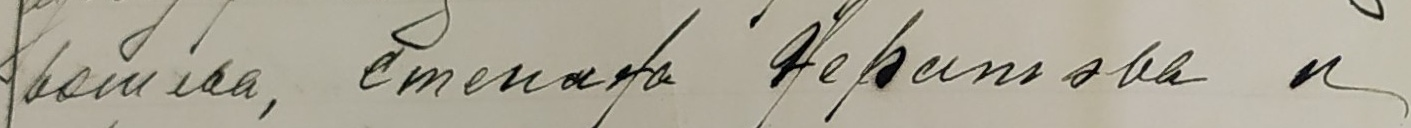

Загрузка модели: filled_long
Модель готова.

Исходная модель:
ротева, этепана Нератова и

После дообучения:
ротева, этепана Нератова и

Правильная транскрипция:
рошева, Степана Нератова и


In [16]:
COMPARE_IMAGE = "data/validation/133601-188.jpg"

compare_path = Path(COMPARE_IMAGE)

if not compare_path.exists():
    raise FileNotFoundError(compare_path)

display(Image(filename=str(compare_path)))

original_engine = OCREngine(
    FINETUNED_MODEL_NAME
)

original_text = original_engine.recognize(
    compare_path
)

finetuned_text = finetuned_engine.recognize(
    compare_path
)

print("\nИсходная модель:")
print(original_text)

print("\nПосле дообучения:")
print(finetuned_text)

ground_truth_path = compare_path.with_suffix(
    ".gt.txt"
)

if ground_truth_path.exists():

    ground_truth = ground_truth_path.read_text(
        encoding="utf-8-sig"
    ).strip()

    print("\nПравильная транскрипция:")
    print(ground_truth)

else:

    ground_truth = ""

    print("\nФайл .gt.txt не найден.")

## 15. График истории обучения

Посмотрим, как изменялась функция потерь
во время дообучения.

Если validation loss начинает увеличиваться,
это может свидетельствовать о переобучении.

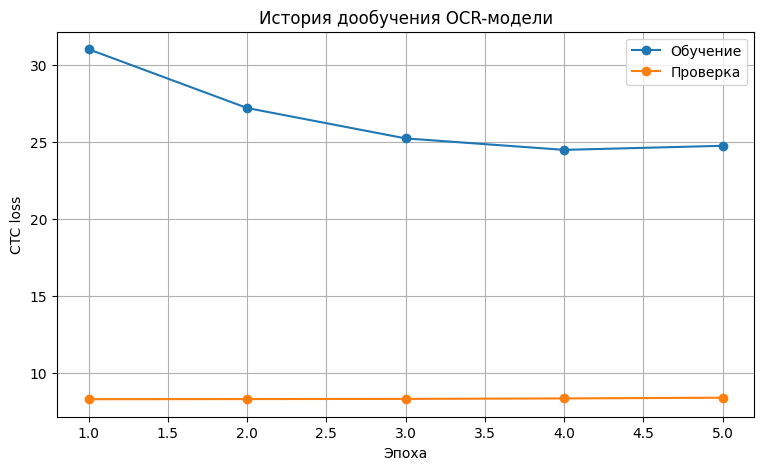

In [17]:
import json
import matplotlib.pyplot as plt

HISTORY_PATH = (
    Path("results")
    / "finetuned_models"
    / FINETUNED_MODEL_NAME
    / FINETUNED_EXPERIMENT
    / "history.json"
)

with open(
    HISTORY_PATH,
    "r",
    encoding="utf-8"
) as file:
    training_history = json.load(file)

epochs = [
    item["epoch"]
    for item in training_history
]

train_losses = [
    item["train_loss"]
    for item in training_history
]

validation_losses = [
    item["validation_loss"]
    for item in training_history
]

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Обучение"
)

if any(
    value is not None
    for value in validation_losses
):

    val_epochs = [
        epoch
        for epoch, value in zip(
            epochs,
            validation_losses
        )
        if value is not None
    ]

    val_values = [
        value
        for value in validation_losses
        if value is not None
    ]

    plt.plot(
        val_epochs,
        val_values,
        marker="o",
        label="Проверка"
    )

plt.xlabel("Эпоха")
plt.ylabel("CTC loss")
plt.title("История дообучения OCR-модели")
plt.grid(True)
plt.legend()
plt.show()

## 16. Сохранение результатов сравнения

Сохраним результаты исходной и дообученной модели
в CSV-файл.

CSV можно открыть в Excel.

In [18]:
import csv

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(exist_ok=True)

COMPARISON_CSV = (
    OUTPUT_DIR / "finetuning_comparison.csv"
)

with open(
    COMPARISON_CSV,
    "w",
    newline="",
    encoding="utf-8-sig"
) as file:

    writer = csv.writer(file)

    writer.writerow([
        "image",
        "model",
        "experiment",
        "original_text",
        "finetuned_text",
        "ground_truth"
    ])

    writer.writerow([
        str(compare_path),
        FINETUNED_MODEL_NAME,
        FINETUNED_EXPERIMENT,
        original_text,
        finetuned_text,
        ground_truth
    ])

print("Результаты сохранены:")
print(COMPARISON_CSV)

Результаты сохранены:
results\finetuning_comparison.csv
